# Bot vs. Human Detection on Web Forms via Keystroke Dynamics

**Course:** UML501 — Machine Learning  
**Syllabus Focus:** Unit 2 (Data Pre-processing) & Unit 4 (Classification)  
**Models:** Random Forest (Baseline), XGBoost, and LightGBM

### Notebook Structure
1. **Section 1:** Data Acquisition (Aalto CHI 2018 Calibrator / Optional KeyRecs & Aalto 136M Loader) + 4-Tier Adversarial Bot Simulator
2. **Section 2:** Signal Cleaning, 18 Behavioral Input Features, Leakage-Free `StratifiedGroupKFold` Split & PCA Visualization
3. **Section 3:** 5-Fold Group Cross-Validation & Held-Out Test Benchmark (`Random Forest` vs. `XGBoost` vs. `LightGBM`)
4. **Section 4:** SHAP Feature Explainability & Sensitivity/Specificity Threshold Analysis
5. **Section 5:** Live Interactive Gradio Web-Form Detector

In [1]:
import os
import sys
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl_config")

import warnings
import time
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    precision_score, recall_score, f1_score,
)
import xgboost as xgb
import lightgbm as lgb
import shap
import gradio as gr

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# Standard clean light theme for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

PALETTE = {
    "Human": "#1b9e77",
    "Tier1_Fixed": "#d95f02",
    "Tier2_UniformJitter": "#7570b3",
    "Tier3_GaussianJitter": "#e7298a",
    "Tier4_Stealthy": "#666666",
}
TIER_ORDER = ["Human", "Tier1_Fixed", "Tier2_UniformJitter", "Tier3_GaussianJitter", "Tier4_Stealthy"]

AALTO_DATA_DIR = None       # Optional: local folder containing Aalto 136M *_keystrokes.txt files
USE_ONLINE_KEYRECS = False  # Set True to fetch KeyRecs free-text.csv online; False uses Aalto CHI 2018 calibrator

print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## Section 1 — Data Acquisition & 4-Tier Adversarial Bot Generation

- **Genuine Human Baseline (`label = 0`):** 240 persistent human user profiles (5 sessions each = 1,200 sessions) calibrated to the Aalto CHI 2018 web-typing study across careful (25%), average (45%), and fast touch typists (30%). Down-Down cadences follow a continuous AR(1) motor rhythm so physical key rollover (`UD < 0`) and sequential correlation arise naturally.
- **4-Tier Adversarial Bot Simulator (`label = 1`):** 240 bot script profiles (60 per tier × 5 sessions = 1,200 bot sessions):
  1. `Tier1_Fixed`: Constant delay (`±1.5 ms`), 0% rollover, 0% backspaces.
  2. `Tier2_UniformJitter`: Random `Uniform(35, 210 ms)` delays, 0% rollover.
  3. `Tier3_GaussianJitter`: Independent normal flight and hold times, 0% rollover.
  4. `Tier4_Stealthy`: Log-normal delays matching human speed, variance, skewness, pauses, synthetic overlap (~3%), and fake backspaces (~3.5%), without human AR(1) autocorrelation.

In [2]:
def _load_keyrecs_online(max_sessions: int = 1200) -> list:
    url = "https://zenodo.org/records/7886743/files/free-text.csv?download=1"
    with urllib.request.urlopen(url, timeout=25) as r:
        df_k = pd.read_csv(io.BytesIO(r.read()), nrows=160000)
    cols_lower = {c.lower(): c for c in df_k.columns}
    user_col = next((cols_lower[k] for k in cols_lower if "participant" in k or k in ("user", "id", "subject")), None)
    hold_col = next((cols_lower[k] for k in cols_lower if "hold" in k or k in ("du.key1.key1", "du", "h")), None)
    ud_col = next((cols_lower[k] for k in cols_lower if "ud." in k or k in ("ud.key1.key2", "ud", "flight")), None)
    key_col = next((cols_lower[k] for k in cols_lower if "key1" in k or "keycode" in k or k == "key"), None)
    if not (user_col and hold_col and ud_col):
        return []

    frames, sid = [], 0
    for uid, grp in df_k.groupby(user_col):
        grp = grp.dropna(subset=[hold_col, ud_col])
        for start in range(0, len(grp) - 45 + 1, 55):
            if sid >= max_sessions:
                return frames
            chunk = grp.iloc[start : start + 55]
            holds = np.clip(chunk[hold_col].astype(float).values, 0.010, 0.800)
            uds = np.clip(chunk[ud_col].astype(float).values, -0.250, 2.500)
            if np.median(np.abs(holds)) > 5.0:
                holds, uds = holds / 1000.0, uds / 1000.0
            kds, kus = [0.0], [float(holds[0])]
            for j in range(1, len(holds)):
                kd_j = max(kds[-1] + 0.015, kus[-1] + float(uds[j]))
                kds.append(kd_j)
                kus.append(kd_j + float(holds[j]))
            bs = (
                chunk[key_col].astype(str).str.lower().str.contains("back|8").astype(int).values
                if key_col else np.zeros(len(holds), dtype=int)
            )
            frames.append(pd.DataFrame({
                "session_id": sid, "user_id": f"keyrecs_{uid}", "label": 0, "bot_tier": "Human",
                "key_down": kds, "key_up": kus, "is_backspace": bs,
            }))
            sid += 1
    return frames


def _build_human_profiles(n_users: int, rng: np.random.Generator) -> list:
    profiles = []
    for u in range(n_users):
        arch = rng.choice(["careful", "average", "fast"], p=[0.25, 0.45, 0.30])
        if arch == "fast":
            base_dd, hold_mu = rng.uniform(0.088, 0.120), rng.uniform(0.100, 0.135)
            hold_sig, ar_phi, bs_rate = rng.uniform(0.20, 0.30), rng.uniform(0.56, 0.72), rng.uniform(0.015, 0.055)
        elif arch == "average":
            base_dd, hold_mu = rng.uniform(0.125, 0.180), rng.uniform(0.095, 0.132)
            hold_sig, ar_phi, bs_rate = rng.uniform(0.21, 0.31), rng.uniform(0.54, 0.70), rng.uniform(0.012, 0.072)
        else:
            base_dd, hold_mu = rng.uniform(0.185, 0.268), rng.uniform(0.090, 0.135)
            hold_sig, ar_phi, bs_rate = rng.uniform(0.22, 0.32), rng.uniform(0.52, 0.68), rng.uniform(0.008, 0.085)
        profiles.append({
            "user_id": f"human_u{u:03d}", "archetype": arch,
            "base_dd": base_dd, "hold_mu": hold_mu, "hold_sig": hold_sig,
            "ar_phi": ar_phi, "bs_rate": bs_rate,
        })
    return profiles


def _simulate_human_session(session_id: int, prof: dict, rng: np.random.Generator) -> pd.DataFrame:
    n_keys = int(rng.integers(24, 45)) if rng.random() < 0.35 else int(rng.integers(45, 105))
    base_dd = prof["base_dd"] * rng.uniform(0.92, 1.08)
    hold_mu = prof["hold_mu"] * rng.uniform(0.92, 1.08)
    hold_sig, phi, bs_rate = prof["hold_sig"], prof["ar_phi"], prof["bs_rate"]

    kds, kus, is_bs = [], [], []
    motor_state = rng.normal(0.0, 0.38)
    phrase_len = int(rng.integers(5, 9))

    for i in range(n_keys):
        motor_state = phi * motor_state + rng.normal(0.0, 0.26)
        phrase_pause = 0.0
        if i > 0 and (i % phrase_len == 0) and rng.random() < 0.38:
            motor_state += rng.uniform(0.35, 0.75)
            phrase_pause = rng.exponential(0.08)
            phrase_len = int(rng.integers(5, 9))

        bs_flag = 1 if (i > 3 and rng.random() < bs_rate) else 0
        if i == 0:
            kd = 0.0
        else:
            if bs_flag:
                motor_state += 0.45
                dd = float(np.clip(rng.lognormal(np.log(max(0.24, base_dd * 1.80)), 0.28), 0.14, 1.8))
            else:
                dd = float(np.exp(np.log(base_dd) + 0.46 * motor_state + rng.normal(0.0, 0.14))) + phrase_pause
                dd = float(np.clip(dd, 0.028, 2.2))
            kd = kds[-1] + dd

        hold = float(np.clip(rng.lognormal(np.log(hold_mu) + 0.05 * motor_state, hold_sig), 0.025, 0.340))
        kds.append(kd)
        kus.append(kd + hold)
        is_bs.append(bs_flag)

    return pd.DataFrame({
        "session_id": session_id, "user_id": prof["user_id"], "label": 0, "bot_tier": "Human",
        "key_down": kds, "key_up": kus, "is_backspace": is_bs,
    })


def _sample_bot_profile(tier: str, user_id: str, rng: np.random.Generator) -> dict:
    if tier == "Tier1_Fixed":
        p = {"base_delay": rng.uniform(0.020, 0.095), "base_hold": rng.uniform(0.015, 0.055)}
    elif tier == "Tier2_UniformJitter":
        p = {"low": rng.uniform(0.035, 0.075), "high": rng.uniform(0.110, 0.210)}
    elif tier == "Tier3_GaussianJitter":
        p = {"mu_ud": rng.uniform(0.075, 0.160), "sig_ud": rng.uniform(0.022, 0.045), "mu_hold": rng.uniform(0.065, 0.108)}
    else:
        p = {
            "base_dd": rng.uniform(0.110, 0.215), "sig_dd": rng.uniform(0.24, 0.35),
            "mu_hold": rng.uniform(0.088, 0.130), "sig_hold": rng.uniform(0.21, 0.31),
            "fake_bs_p": rng.uniform(0.012, 0.058), "fake_roll_p": rng.uniform(0.010, 0.052),
        }
    p.update({"user_id": user_id, "tier": tier})
    return p


def _simulate_bot_session(session_id: int, prof_or_tier, rng: np.random.Generator, n_keys: int = None) -> pd.DataFrame:
    if isinstance(prof_or_tier, str):
        prof = _sample_bot_profile(prof_or_tier, f"bot_{prof_or_tier}_{session_id}", rng)
    else:
        prof = prof_or_tier

    tier = prof["tier"]
    if n_keys is None:
        n_keys = int(rng.integers(24, 45)) if rng.random() < 0.35 else int(rng.integers(45, 105))
    kds, kus, is_bs = [], [], []

    if tier == "Tier1_Fixed":
        bd, bh = prof["base_delay"], prof["base_hold"]
        for i in range(n_keys):
            hold = max(0.005, bh + rng.normal(0, 0.0015))
            ud = max(0.005, bd + rng.normal(0, 0.0015))
            kd = 0.0 if i == 0 else kus[-1] + ud
            kds.append(kd); kus.append(kd + hold); is_bs.append(0)
    elif tier == "Tier2_UniformJitter":
        low, high = prof["low"], prof["high"]
        for i in range(n_keys):
            hold = rng.uniform(0.030, 0.085)
            ud = rng.uniform(low, high)
            kd = 0.0 if i == 0 else kus[-1] + ud
            kds.append(kd); kus.append(kd + hold); is_bs.append(0)
    elif tier == "Tier3_GaussianJitter":
        mu_ud, sig_ud, mu_hold = prof["mu_ud"], prof["sig_ud"], prof["mu_hold"]
        for i in range(n_keys):
            hold = float(np.clip(rng.normal(mu_hold, 0.014), 0.020, 0.195))
            ud = float(np.clip(rng.normal(mu_ud, sig_ud), 0.008, 0.380))
            kd = 0.0 if i == 0 else kus[-1] + ud
            kds.append(kd); kus.append(kd + hold); is_bs.append(0)
    else:
        base_dd = prof["base_dd"] * rng.uniform(0.92, 1.08)
        sig_dd = prof["sig_dd"]
        mu_hold = prof["mu_hold"] * rng.uniform(0.92, 1.08)
        sig_hold = prof["sig_hold"]
        fake_bs_p, fake_roll_p = prof["fake_bs_p"], prof["fake_roll_p"]
        for i in range(n_keys):
            hold = float(np.clip(rng.lognormal(np.log(mu_hold), sig_hold), 0.025, 0.340))
            bs_flag = 1 if (i > 4 and rng.random() < fake_bs_p) else 0
            if i == 0:
                kd = 0.0
            else:
                if bs_flag:
                    dd = float(np.clip(rng.lognormal(np.log(max(0.18, base_dd * 1.45)), 0.28), 0.10, 1.3))
                    kd = kds[-1] + dd
                elif rng.random() < fake_roll_p:
                    ud = -float(rng.uniform(0.004, 0.028))
                    kd = max(kds[-1] + 0.022, kus[-1] + ud)
                else:
                    dd = float(np.clip(rng.lognormal(np.log(base_dd), sig_dd), 0.035, 1.8))
                    if rng.random() < 0.06:
                        dd += rng.exponential(0.10)
                    kd = max(kds[-1] + dd, kus[-1] + 0.002)
            kds.append(kd); kus.append(kd + hold); is_bs.append(bs_flag)

    return pd.DataFrame({
        "session_id": session_id, "user_id": prof["user_id"], "label": 1, "bot_tier": tier,
        "key_down": kds, "key_up": kus, "is_backspace": is_bs,
    })


def build_raw_keystroke_dataset(n_human_users=240, sessions_per_user=5, n_bot_profiles_per_tier=60):
    rng, frames, source = np.random.default_rng(SEED), [], ""
    n_human = n_human_users * sessions_per_user

    if AALTO_DATA_DIR and Path(AALTO_DATA_DIR).exists():
        for fpath in sorted(Path(AALTO_DATA_DIR).glob("*_keystrokes.txt"))[:n_human]:
            raw = pd.read_csv(fpath, sep="\t", usecols=["PARTICIPANT_ID", "PRESS_TIME", "RELEASE_TIME", "KEYCODE"]).dropna().head(100)
            if len(raw) < 20:
                continue
            t0 = raw["PRESS_TIME"].iloc[0]
            frames.append(pd.DataFrame({
                "session_id": len(frames), "user_id": f"aalto_{raw['PARTICIPANT_ID'].iloc[0]}", "label": 0, "bot_tier": "Human",
                "key_down": (raw["PRESS_TIME"].values - t0) / 1000.0,
                "key_up": (raw["RELEASE_TIME"].values - t0) / 1000.0,
                "is_backspace": (raw["KEYCODE"].values == 8).astype(int),
            }))
        source = f"Aalto 136M Local Files ({len(frames)} sessions)"

    if not frames and USE_ONLINE_KEYRECS:
        try:
            frames = _load_keyrecs_online(max_sessions=n_human)
            if frames:
                source = f"KeyRecs Zenodo ({len(frames)} sessions)"
        except Exception as exc:
            print(f"KeyRecs online fetch skipped ({type(exc).__name__}); using Aalto CHI 2018 calibrator.")

    if not frames:
        for prof in _build_human_profiles(n_human_users, rng):
            for _ in range(sessions_per_user):
                frames.append(_simulate_human_session(len(frames), prof, rng))
        source = f"Aalto CHI 2018 Calibrator ({len(frames)} sessions across {n_human_users} persistent user profiles)"

    sid = len(frames)
    for tier in ["Tier1_Fixed", "Tier2_UniformJitter", "Tier3_GaussianJitter", "Tier4_Stealthy"]:
        for k in range(n_bot_profiles_per_tier):
            bot_prof = _sample_bot_profile(tier, f"bot_{tier}_u{k:02d}", rng)
            for _ in range(sessions_per_user):
                frames.append(_simulate_bot_session(sid, bot_prof, rng))
                sid += 1

    df = pd.concat(frames, ignore_index=True)
    summary = df.groupby("bot_tier").agg(
        Profiles=("user_id", "nunique"),
        Sessions=("session_id", "nunique"),
        Keystrokes=("key_down", "count"),
        Avg_Keys=("key_down", lambda s: len(s) / df.loc[s.index, "session_id"].nunique()),
        Backspace_Pct=("is_backspace", lambda s: s.mean() * 100),
    ).reindex(TIER_ORDER)
    print(f"Human source: {source} | Total events: {len(df):,}")
    display(summary.round(2))
    return df


raw_events_df = build_raw_keystroke_dataset()

Human source: Aalto CHI 2018 Calibrator (1200 sessions across 240 persistent user profiles) | Total events: 144,281


,Profiles,Sessions,Keystrokes,Avg_Keys,Backspace_Pct
bot_tier,,,,,
Human,240,1200,71421,59.52,3.89
Tier1_Fixed,60,300,17957,59.86,0.00
Tier2_UniformJitter,60,300,18766,62.55,0.00
Tier3_GaussianJitter,60,300,18175,60.58,0.00
Tier4_Stealthy,60,300,17962,59.87,3.52


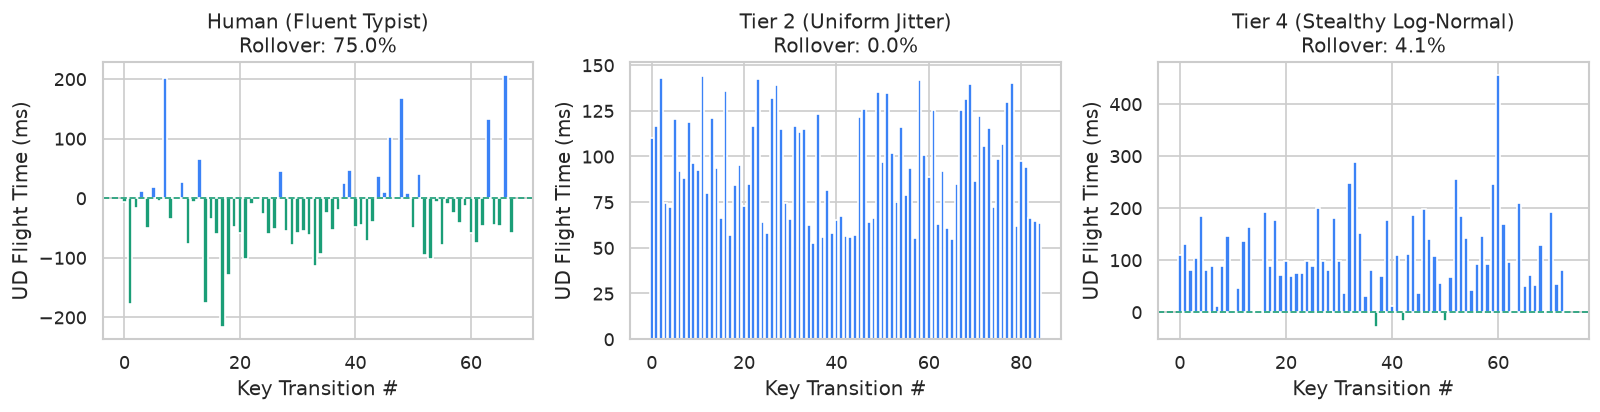

In [3]:
# Compare sample Up-Down flight sequences for a Human vs. Tier 2 Bot vs. Tier 4 Stealthy Bot
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
examples = [
    ("Human", "Human (Fluent Typist)"),
    ("Tier2_UniformJitter", "Tier 2 (Uniform Jitter)"),
    ("Tier4_Stealthy", "Tier 4 (Stealthy Log-Normal)"),
]
for ax, (tier, title) in zip(axes, examples):
    sub = raw_events_df[raw_events_df["bot_tier"] == tier]
    sids = sub["session_id"].unique()
    sess = sub[sub["session_id"] == sids[2]]
    kd, ku = sess["key_down"].values, sess["key_up"].values
    ud_ms = (kd[1:] - ku[:-1]) * 1000.0
    colors = ["#1b9e77" if v < 0 else "#3b82f6" for v in ud_ms]
    ax.bar(range(len(ud_ms)), ud_ms, color=colors, width=0.8)
    ax.axhline(0, color="#1b9e77", linestyle="--", linewidth=1)
    ax.set_title(f"{title}\nRollover: {(ud_ms < 0).mean()*100:.1f}%")
    ax.set_xlabel("Key Transition #")
    ax.set_ylabel("UD Flight Time (ms)")

plt.tight_layout()
plt.show()

---
## Section 2 — Data Pre-processing & 18 Behavioral Features (UML501 Unit 2)

1. **Signal Cleaning:** Clip holds to `[5 ms, 1.0 s]`, cap idle flight gaps at `3.0 s`, and **preserve negative Up-Down rollover times** down to `-250 ms`.
2. **18 Engineered Input Parameters:**
   - **Flight-Time Micro-Variations (7):** `ud_mean`, `ud_std`, `ud_cv` (normalized by `mean(|UD|) + 0.01`), `ud_iqr`, `ud_skew`, `ud_kurtosis`, `ud_lag1_autocorr`
   - **Down-Down Cadence (3):** `dd_mean`, `dd_std`, `dd_cv`
   - **Hold / Dwell Dynamics (4):** `hold_mean`, `hold_std`, `hold_cv`, `dwell_flight_ratio`
   - **Rollover & Error Dynamics (4):** `rollover_ratio`, `backspace_rate`, `correction_burst_latency`, `wpm`
3. **Leakage-Free Train/Test Split:** `StratifiedGroupKFold` (5 folds) grouped by `user_id` and stratified by `bot_tier`, ensuring zero participant overlap between Train (1,920 sessions) and Test (480 sessions).

In [4]:
FEATURE_COLS = [
    "ud_mean", "ud_std", "ud_cv", "ud_iqr", "ud_skew", "ud_kurtosis", "ud_lag1_autocorr",
    "dd_mean", "dd_std", "dd_cv",
    "hold_mean", "hold_std", "hold_cv", "dwell_flight_ratio",
    "rollover_ratio", "backspace_rate", "correction_burst_latency", "wpm",
]


def extract_session_features(sub: pd.DataFrame) -> dict:
    kd = sub["key_down"].values.astype(float)
    ku = sub["key_up"].values.astype(float)
    bs = sub["is_backspace"].values.astype(int)

    holds = np.clip(ku - kd, 0.005, 1.0)
    ud = np.clip(kd[1:] - ku[:-1], -0.25, 3.0)
    dd = np.clip(np.diff(kd), 0.005, 3.0)

    ud_mean = float(np.mean(ud))
    ud_std = float(np.std(ud))
    ud_cv = float(ud_std / (float(np.mean(np.abs(ud))) + 0.01))
    ud_iqr = float(np.percentile(ud, 75) - np.percentile(ud, 25))
    ud_skew = float(stats.skew(ud)) if ud_std > 1e-6 else 0.0
    ud_kurt = float(stats.kurtosis(ud)) if ud_std > 1e-6 else 0.0
    ud_lag1 = (
        float(np.corrcoef(ud[:-1], ud[1:])[0, 1])
        if len(ud) > 3 and np.std(ud[:-1]) > 1e-6 and np.std(ud[1:]) > 1e-6 else 0.0
    )

    dd_mean, dd_std = float(np.mean(dd)), float(np.std(dd))
    dd_cv = float(dd_std / (dd_mean + 0.01))

    hold_mean, hold_std = float(np.mean(holds)), float(np.std(holds))
    hold_cv = float(hold_std / (hold_mean + 0.01))
    dwell_flight_ratio = float(hold_mean / (abs(ud_mean) + 0.02))

    rollover_ratio = float(np.mean(ud < 0))
    backspace_rate = float(np.mean(bs))
    bs_indices = np.where(bs[1:] == 1)[0]
    corr_latency = float(np.mean(ud[bs_indices])) if len(bs_indices) > 0 else 0.0
    total_sec = max(0.5, float(ku[-1] - kd[0]))
    wpm = float((len(kd) / 5.0) / (total_sec / 60.0))

    return {
        "session_id": int(sub["session_id"].iloc[0]), "user_id": str(sub["user_id"].iloc[0]),
        "label": int(sub["label"].iloc[0]), "bot_tier": str(sub["bot_tier"].iloc[0]),
        "ud_mean": ud_mean, "ud_std": ud_std, "ud_cv": ud_cv, "ud_iqr": ud_iqr,
        "ud_skew": ud_skew, "ud_kurtosis": ud_kurt, "ud_lag1_autocorr": ud_lag1,
        "dd_mean": dd_mean, "dd_std": dd_std, "dd_cv": dd_cv,
        "hold_mean": hold_mean, "hold_std": hold_std, "hold_cv": hold_cv,
        "dwell_flight_ratio": dwell_flight_ratio, "rollover_ratio": rollover_ratio,
        "backspace_rate": backspace_rate, "correction_burst_latency": corr_latency, "wpm": wpm,
    }


features_df = pd.DataFrame([extract_session_features(g) for _, g in raw_events_df.groupby("session_id")])
features_df[FEATURE_COLS] = features_df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0)
assert not features_df[FEATURE_COLS].isna().any().any()

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(features_df[FEATURE_COLS], features_df["bot_tier"], features_df["user_id"]))
train_df = features_df.iloc[train_idx].reset_index(drop=True)
test_df = features_df.iloc[test_idx].reset_index(drop=True)
assert set(train_df["user_id"]).isdisjoint(set(test_df["user_id"])), "User leakage detected!"

X_train, y_train = train_df[FEATURE_COLS], train_df["label"].values
g_train, tier_train = train_df["user_id"].values, train_df["bot_tier"].values
X_test, y_test = test_df[FEATURE_COLS], test_df["label"].values

# StandardScaler + 2D PCA for separability visualization (tree models use raw physical units)
pca_2d = PCA(n_components=2, random_state=SEED)
pca_coords = pca_2d.fit_transform(StandardScaler().fit_transform(features_df[FEATURE_COLS]))
pca_df = features_df[["bot_tier"]].copy()
pca_df["PC1"], pca_df["PC2"] = pca_coords[:, 0], pca_coords[:, 1]

print(f"Train sessions: {len(train_df)} | Held-Out Test sessions: {len(test_df)} | User overlap: 0")
feat_summary = features_df.groupby("bot_tier")[
    ["rollover_ratio", "ud_lag1_autocorr", "ud_cv", "dd_cv", "hold_cv", "ud_skew", "backspace_rate", "correction_burst_latency", "wpm"]
].mean().reindex(TIER_ORDER)
display(feat_summary.round(3))

Train sessions: 1920 | Held-Out Test sessions: 480 | User overlap: 0


,rollover_ratio,ud_lag1_autocorr,ud_cv,dd_cv,hold_cv,ud_skew,backspace_rate,correction_burst_latency,wpm
bot_tier,,,,,,,,,
Human,0.249,0.113,0.825,0.307,0.241,1.173,0.038,0.159,73.104
Tier1_Fixed,0.000,-0.024,0.026,0.022,0.035,0.004,0.000,0.000,146.359
Tier2_UniformJitter,0.000,-0.025,0.253,0.193,0.232,-0.001,0.000,0.000,72.442
Tier3_GaussianJitter,0.000,-0.027,0.273,0.171,0.143,-0.001,0.000,0.000,60.645
Tier4_Stealthy,0.029,-0.013,0.836,0.304,0.242,1.447,0.035,0.102,68.717


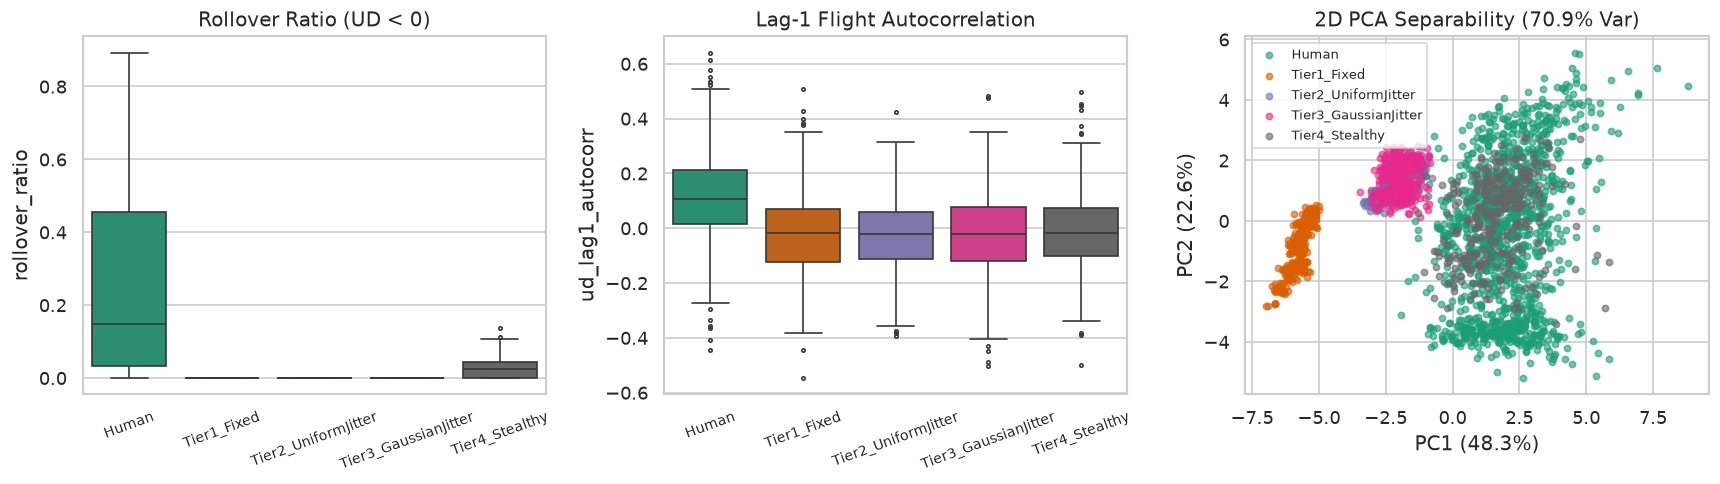

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

sns.boxplot(data=features_df, x="bot_tier", y="rollover_ratio", hue="bot_tier", order=TIER_ORDER, palette=PALETTE, legend=False, ax=axes[0], fliersize=2)
axes[0].set_title("Rollover Ratio (UD < 0)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20, labelsize=8.5)

sns.boxplot(data=features_df, x="bot_tier", y="ud_lag1_autocorr", hue="bot_tier", order=TIER_ORDER, palette=PALETTE, legend=False, ax=axes[1], fliersize=2)
axes[1].set_title("Lag-1 Flight Autocorrelation")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20, labelsize=8.5)

for t in TIER_ORDER:
    sub_p = pca_df[pca_df["bot_tier"] == t]
    axes[2].scatter(sub_p["PC1"], sub_p["PC2"], s=14, alpha=0.6, color=PALETTE[t], label=t)
axes[2].set_title(f"2D PCA Separability ({pca_2d.explained_variance_ratio_.sum()*100:.1f}% Var)")
axes[2].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
axes[2].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
axes[2].legend(loc="best", fontsize=7.5)

plt.tight_layout()
plt.show()

---
## Section 3 — Classification & Model Benchmarking (UML501 Unit 4)

We evaluate **Random Forest** (bagging baseline) against **XGBoost** and **LightGBM** using 5-Fold Stratified Group CV on the training set and single-pass evaluation on the 480 unseen-user test sessions.

In [6]:
def compute_eer(y_true, y_prob):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    fnr = 1.0 - tpr
    idx = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[idx] + fnr[idx]) / 2.0)


def evaluate_predictions(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Sensitivity": tp / (tp + fn + 1e-9),
        "Specificity": tn / (tn + fp + 1e-9),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "EER": compute_eer(y_true, y_prob),
    }


base_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=250, max_depth=12, min_samples_leaf=3, random_state=SEED, n_jobs=-1
    ),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.85,
        colsample_bytree=0.85, reg_lambda=1.0, eval_metric="logloss", random_state=SEED, n_jobs=-1
    ),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=250, num_leaves=23, max_depth=5, learning_rate=0.05,
        min_child_samples=20, subsample=0.85, colsample_bytree=0.85, reg_lambda=2.0,
        random_state=SEED, verbose=-1, n_jobs=-1
    ),
}

cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
models, results_rows, test_probs, tier_catch_rates = {}, [], {}, {}

for name, template_clf in base_models.items():
    cv_aucs, cv_f1s = [], []
    for f_tr, f_va in cv_splitter.split(X_train, tier_train, g_train):
        fold_clf = clone(template_clf)
        fold_clf.fit(X_train.iloc[f_tr], y_train[f_tr])
        va_probs = fold_clf.predict_proba(X_train.iloc[f_va])[:, 1]
        cv_aucs.append(roc_auc_score(y_train[f_va], va_probs))
        cv_f1s.append(f1_score(y_train[f_va], (va_probs >= 0.5).astype(int), zero_division=0))

    clf = clone(template_clf).fit(X_train, y_train)
    models[name] = clf
    probs = clf.predict_proba(X_test)[:, 1]
    test_probs[name] = probs

    m = evaluate_predictions(y_test, probs)
    m.update({"CV AUC Mean": np.mean(cv_aucs), "CV AUC Std": np.std(cv_aucs), "CV F1 Mean": np.mean(cv_f1s), "Model": name})
    results_rows.append(m)
    tier_catch_rates[name] = {
        t: float(np.mean(probs[(test_df["bot_tier"] == t).values] >= 0.5)) * 100.0
        for t in ["Tier1_Fixed", "Tier2_UniformJitter", "Tier3_GaussianJitter", "Tier4_Stealthy"]
    }

cols_order = ["CV AUC Mean", "CV AUC Std", "CV F1 Mean", "ROC-AUC", "F1-Score", "Sensitivity", "Specificity", "Precision", "EER"]
leaderboard_df = pd.DataFrame(results_rows).set_index("Model")[cols_order].sort_values("ROC-AUC", ascending=False)
best_model_name = leaderboard_df.index[0]
best_model = models[best_model_name]

print(f"Best Model: {best_model_name}")
display(leaderboard_df.round(4))

tier_df = pd.DataFrame(tier_catch_rates).T.reindex(leaderboard_df.index)
print("\nPer-Tier Bot Catch Rate (%) at Threshold = 0.50:")
display(tier_df.round(1))

Best Model: XGBoost


,CV AUC Mean,CV AUC Std,CV F1 Mean,ROC-AUC,F1-Score,Sensitivity,Specificity,Precision,EER
Model,,,,,,,,,
XGBoost,0.9957,0.0017,0.9688,0.9969,0.9750,0.975,0.9750,0.9750,0.0229
LightGBM,0.9954,0.0020,0.9673,0.9968,0.9730,0.975,0.9708,0.9710,0.0250
Random Forest,0.9951,0.0029,0.9642,0.9955,0.9641,0.950,0.9792,0.9785,0.0458



Per-Tier Bot Catch Rate (%) at Threshold = 0.50:


,Tier1_Fixed,Tier2_UniformJitter,Tier3_GaussianJitter,Tier4_Stealthy
Model,,,,
XGBoost,100.0,100.0,100.0,90.0
LightGBM,100.0,100.0,100.0,90.0
Random Forest,100.0,100.0,100.0,80.0


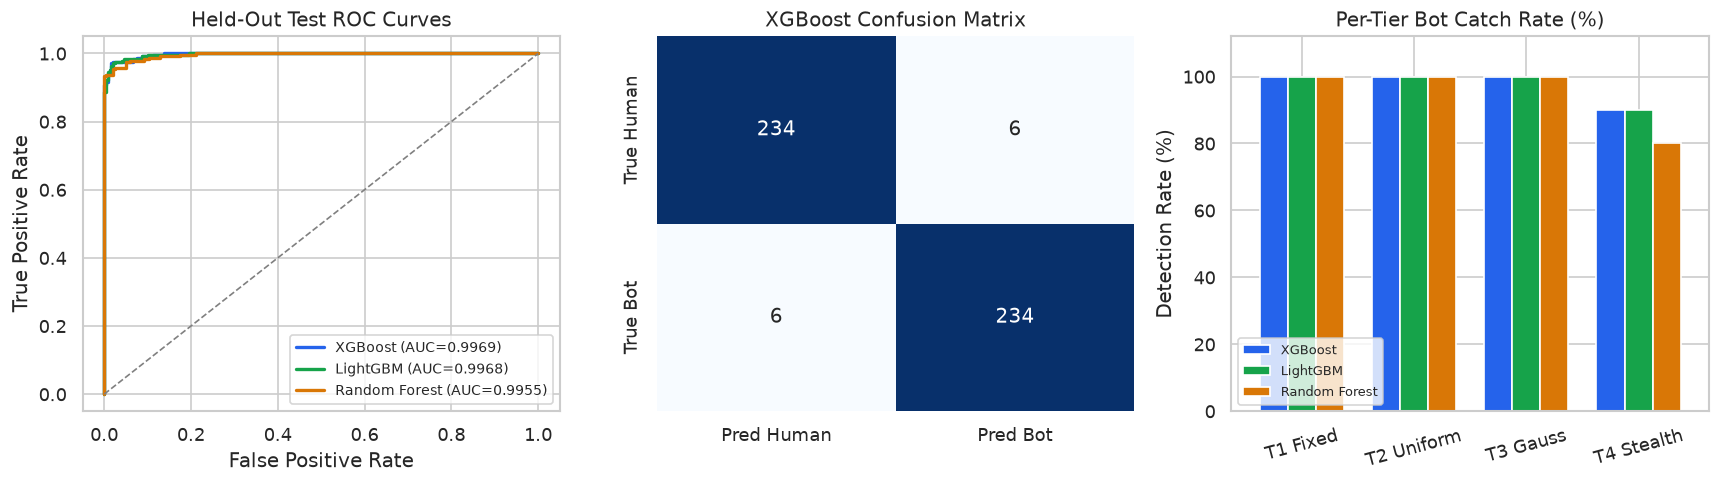

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
m_colors = {"XGBoost": "#2563eb", "LightGBM": "#16a34a", "Random Forest": "#d97706"}

# 1. ROC Curves
for nm in ["XGBoost", "LightGBM", "Random Forest"]:
    fpr, tpr, _ = roc_curve(y_test, test_probs[nm])
    axes[0].plot(fpr, tpr, label=f"{nm} (AUC={roc_auc_score(y_test, test_probs[nm]):.4f})", color=m_colors[nm], linewidth=2)
axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[0].set_title("Held-Out Test ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8.5)

# 2. Best Model Confusion Matrix
cm = confusion_matrix(y_test, (test_probs[best_model_name] >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Pred Human", "Pred Bot"], yticklabels=["True Human", "True Bot"])
axes[1].set_title(f"{best_model_name} Confusion Matrix")

# 3. Per-Tier Catch Rate Comparison
tier_df[["Tier1_Fixed", "Tier2_UniformJitter", "Tier3_GaussianJitter", "Tier4_Stealthy"]].T.plot(
    kind="bar", ax=axes[2], color=[m_colors[m] for m in tier_df.index], width=0.75
)
axes[2].set_title("Per-Tier Bot Catch Rate (%)")
axes[2].set_ylabel("Detection Rate (%)")
axes[2].set_ylim(0, 112)
axes[2].set_xticklabels(["T1 Fixed", "T2 Uniform", "T3 Gauss", "T4 Stealth"], rotation=15)
axes[2].legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

---
## Section 4 — SHAP Explainability & Operating Threshold Analysis

We use **TreeSHAP** to audit which behavioral signals drive `XGBoost` decisions and examine the Sensitivity vs. Specificity tradeoff across operating thresholds (`0.35` High-Security Login vs. `0.65` Low-Friction Checkout).

In [8]:
explainer = shap.TreeExplainer(best_model)
raw_shap = explainer.shap_values(X_test)
if isinstance(raw_shap, list):
    shap_vals = np.array(raw_shap[1])
elif getattr(raw_shap, "ndim", 2) == 3:
    shap_vals = raw_shap[:, :, 1]
else:
    shap_vals = np.array(raw_shap)

mean_abs_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=FEATURE_COLS).sort_values(ascending=False)
shap_table = pd.DataFrame({
    "Mean |SHAP|": mean_abs_shap.head(10),
    "Share (%)": (mean_abs_shap.head(10) / mean_abs_shap.sum()) * 100.0,
})
print(f"Top 10 Features Driving {best_model_name}:")
display(shap_table.round(4))

Top 10 Features Driving XGBoost:


,Mean |SHAP|,Share (%)
rollover_ratio,2.5291,24.5000
hold_std,1.8492,17.9132
ud_lag1_autocorr,0.5830,5.6476
ud_iqr,0.5621,5.4455
ud_kurtosis,0.5571,5.3971
correction_burst_latency,0.5357,5.1891
dd_cv,0.5155,4.9941
ud_cv,0.4883,4.7305
dd_mean,0.4726,4.5778
ud_std,0.4379,4.2424


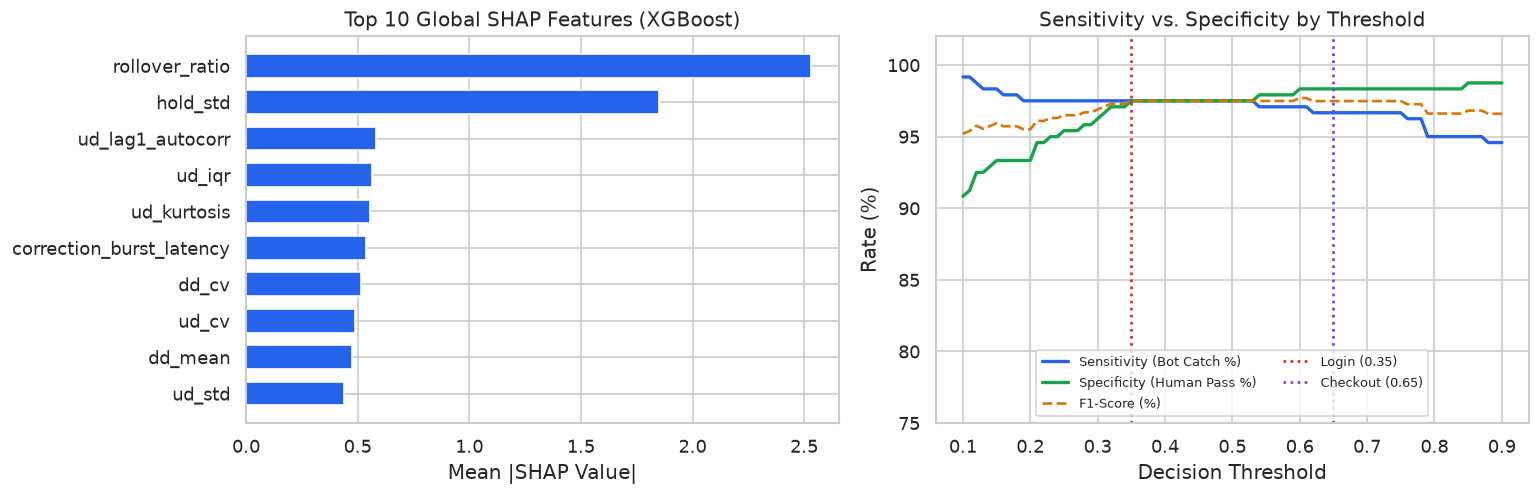

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

top10 = mean_abs_shap.head(10)[::-1]
axes[0].barh(top10.index, top10.values, color="#2563eb", height=0.65)
axes[0].set_title(f"Top 10 Global SHAP Features ({best_model_name})")
axes[0].set_xlabel("Mean |SHAP Value|")

ths = np.linspace(0.10, 0.90, 81)
sens_list, spec_list, f1_list = [], [], []
for th in ths:
    ev = evaluate_predictions(y_test, test_probs[best_model_name], threshold=float(th))
    sens_list.append(ev["Sensitivity"] * 100)
    spec_list.append(ev["Specificity"] * 100)
    f1_list.append(ev["F1-Score"] * 100)

axes[1].plot(ths, sens_list, label="Sensitivity (Bot Catch %)", color="#2563eb", linewidth=2)
axes[1].plot(ths, spec_list, label="Specificity (Human Pass %)", color="#16a34a", linewidth=2)
axes[1].plot(ths, f1_list, label="F1-Score (%)", color="#d97706", linestyle="--", linewidth=1.6)
axes[1].axvline(0.35, color="#dc2626", linestyle=":", linewidth=1.6, label="Login (0.35)")
axes[1].axvline(0.65, color="#7c3aed", linestyle=":", linewidth=1.6, label="Checkout (0.65)")
axes[1].set_title("Sensitivity vs. Specificity by Threshold")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("Rate (%)")
axes[1].set_ylim(75, 102)
axes[1].legend(loc="lower center", ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

---
## Section 5 — Live Gradio Web-Form Detector

Type naturally in the Gradio textbox below—keystroke arrival timestamps are captured cleanly in Python via Gradio's `.input()` hook without storing any text—or test any of the 4 simulated bot tiers in one click.  
*(If your IDE preview renders embedded iframes read-only, open the printed `http://127.0.0.1:7860/` URL directly in your browser.)*

In [10]:
def _plot_rhythm(sub: pd.DataFrame, label_str: str):
    kd, ku = sub["key_down"].values, sub["key_up"].values
    ud_ms = (kd[1:] - ku[:-1]) * 1000.0
    hold_ms = (ku - kd) * 1000.0

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    bar_cols = ["#1b9e77" if v < 0 else "#3b82f6" for v in ud_ms]
    axes[0].bar(range(len(ud_ms)), ud_ms, color=bar_cols, width=0.8)
    axes[0].axhline(0, color="#1b9e77", linestyle="--", linewidth=1)
    axes[0].set_title(f"{label_str} — UD Flight Times (ms)")
    axes[0].set_xlabel("Transition #")
    axes[0].set_ylabel("UD (ms)")

    axes[1].plot(range(len(hold_ms)), hold_ms, marker="o", markersize=3.5, color="#2563eb", linewidth=1.5)
    axes[1].set_title("Key Hold Duration (ms)")
    axes[1].set_xlabel("Keystroke #")
    axes[1].set_ylabel("Hold (ms)")
    plt.tight_layout()
    return fig


def record_keystroke(text: str, state: tuple):
    now = time.perf_counter()
    prev_text, events = state
    events = list(events)
    delta = len(text) - len(prev_text)

    if delta < 0:
        events.append((now, True))
    elif delta > 0:
        last_t = events[-1][0] if events else now - 0.12 * delta
        step = max(0.015, (now - last_t) / delta)
        for k in range(delta):
            events.append((last_t + step * (k + 1), False))

    n = len(events)
    msg = f"**{n} keystrokes captured** — {'Ready to analyze!' if n >= 12 else 'type at least 12 characters.'}"
    return (text, events), msg


def _score_dataframe(sub: pd.DataFrame, source_label: str):
    feats = extract_session_features(sub)
    X_live = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)
    bot_prob = float(best_model.predict_proba(X_live)[0, 1])
    verdict = "BOT DETECTED" if bot_prob >= 0.50 else "HUMAN VERIFIED"
    conf = bot_prob * 100 if bot_prob >= 0.50 else (1.0 - bot_prob) * 100

    summary_md = (
        f"### Verdict: **{verdict}** ({conf:.1f}% confidence)\n"
        f"- **Model:** {best_model_name} | **Source:** {source_label} ({len(sub)} keystrokes)\n"
        f"- **Bot Probability:** `{bot_prob:.3f}` | **WPM:** `{feats['wpm']:.1f}` | "
        f"**Rollover:** `{feats['rollover_ratio']*100:.1f}%` | **Lag-1 AC:** `{feats['ud_lag1_autocorr']:.3f}` | "
        f"**Backspace Rate:** `{feats['backspace_rate']*100:.1f}%`"
    )
    fig = _plot_rhythm(sub, source_label)
    telemetry = pd.DataFrame({
        "Feature": ["rollover_ratio", "ud_lag1_autocorr", "ud_mean (ms)", "ud_std (ms)", "ud_cv", "hold_mean (ms)", "hold_cv", "backspace_rate", "wpm"],
        "Value": [
            round(feats["rollover_ratio"], 3), round(feats["ud_lag1_autocorr"], 3),
            round(feats["ud_mean"] * 1000, 1), round(feats["ud_std"] * 1000, 1),
            round(feats["ud_cv"], 3), round(feats["hold_mean"] * 1000, 1),
            round(feats["hold_cv"], 3), round(feats["backspace_rate"], 3), round(feats["wpm"], 1),
        ],
    })
    return summary_md, fig, telemetry


def analyze_live_typing(state: tuple):
    _, events = state
    if len(events) < 12:
        return f"Need at least 12 keystrokes (currently {len(events)}). Please type naturally in the box above.", None, pd.DataFrame()

    t0 = events[0][0]
    kds = [t - t0 for t, _ in events]
    # Standard ~95 ms key hold estimate from arrival timestamps
    kus = [kd + 0.095 for kd in kds]
    bs = [1 if is_bs else 0 for _, is_bs in events]

    sub = pd.DataFrame({
        "session_id": 0, "user_id": "live", "label": 0, "bot_tier": "Live Typing",
        "key_down": kds, "key_up": kus, "is_backspace": bs,
    })
    return _score_dataframe(sub, "Live Human Typing")


def simulate_bot_live(tier_label: str):
    tier_map = {
        "Tier 1 — Fixed Delay": "Tier1_Fixed",
        "Tier 2 — Uniform Jitter": "Tier2_UniformJitter",
        "Tier 3 — Gaussian Jitter": "Tier3_GaussianJitter",
        "Tier 4 — Stealthy Log-Normal": "Tier4_Stealthy",
    }
    tier = tier_map.get(tier_label, "Tier4_Stealthy")
    sub = _simulate_bot_session(9999, tier, np.random.default_rng(), n_keys=55)
    return _score_dataframe(sub, f"Simulated {tier_label}")

In [11]:
with gr.Blocks(title="UML501 Keystroke Bot Detector") as demo:
    gr.Markdown(f"## Web-Form Bot vs. Human Keystroke Detector ({best_model_name})")
    gr.Markdown("Type a sentence naturally in the text box below and click **Analyze My Typing**, or test any simulated bot tier.")

    key_state = gr.State(("", []))

    with gr.Row():
        with gr.Column(scale=2):
            live_input = gr.Textbox(
                label="Web Form Input (Type naturally)",
                placeholder="Type a quick sentence here (feel free to fix typos with Backspace)...",
                lines=3,
                interactive=True,
            )
            status_md = gr.Markdown("0 keystrokes captured — type at least 12 characters.")
            with gr.Row():
                analyze_btn = gr.Button("Analyze My Typing", variant="primary")
                reset_btn = gr.Button("Reset")

        with gr.Column(scale=1):
            bot_radio = gr.Radio(
                choices=[
                    "Tier 1 — Fixed Delay",
                    "Tier 2 — Uniform Jitter",
                    "Tier 3 — Gaussian Jitter",
                    "Tier 4 — Stealthy Log-Normal",
                ],
                value="Tier 4 — Stealthy Log-Normal",
                label="Simulate Adversarial Bot",
            )
            sim_btn = gr.Button("Simulate & Detect Bot", variant="stop")

    verdict_out = gr.Markdown()
    with gr.Row():
        plot_out = gr.Plot(label="Keystroke Rhythm")
        table_out = gr.Dataframe(label="Extracted Features")

    live_input.input(record_keystroke, inputs=[live_input, key_state], outputs=[key_state, status_md])
    analyze_btn.click(analyze_live_typing, inputs=[key_state], outputs=[verdict_out, plot_out, table_out])
    reset_btn.click(
        lambda: ("", ("", []), "0 keystrokes captured — type at least 12 characters.", "", None, pd.DataFrame()),
        outputs=[live_input, key_state, status_md, verdict_out, plot_out, table_out],
    )
    sim_btn.click(simulate_bot_live, inputs=[bot_radio], outputs=[verdict_out, plot_out, table_out])

in_colab = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
headless_exec = bool(os.environ.get("NBCONVERT_EXEC"))

_, local_url, share_url = demo.launch(
    inline=True,
    share=in_colab,
    prevent_thread_lock=headless_exec,
    quiet=headless_exec,
)
print(f"Gradio UI running at: {share_url or local_url}")
if headless_exec:
    demo.close()

Gradio UI running at: http://127.0.0.1:7860/
Closing server running on port: 7860
